# Классификация эмоций по сигналам ЭЭГ (датасет SEED)

Лабораторная работа. Построен алгоритм классификации эмоционального состояния человека
по многоканальной записи ЭЭГ в трёхклассовой постановке:

* **+1** - положительная эмоция
* **0** - нейтральное состояние
* **-1** - отрицательная эмоция

Данные: открытый набор **SEED** (версия `Preprocessed_EEG`, 200 Гц, монтаж 62 канала по системе 10–20).
На каждой сессии испытуемому показывали 15 клипов (примерно 4 мин), по видеофрагменту на
каждую пробу; одна метка ставится на весь клип.


In [18]:
import os
import sys
import time
import warnings

sys.path.insert(0, os.getcwd())

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
import seaborn as sns
from concurrent.futures import ThreadPoolExecutor

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from features import (CH_NAMES, FEATS_PER_CHANNEL, FEATURE_NAMES,
                      batched_psd, extract_features_from_trial)
from preprocess import (list_session_files, load_trials_from_file,
                        normalize_trial, preprocess_trial, process_one_file)

warnings.filterwarnings('ignore')

%matplotlib inline

DATA_DIR = '../data/prep'          
CACHE_FILE = '../data/features_cache.npy' 
FS = 200                           
SEED = 100                          
CLASS_NAMES = ['negative', 'neutral', 'positive']
N_WORKERS = min(6, os.cpu_count() or 1)

print('ЭЭГ-каналы (монт. 10-20):', len(CH_NAMES))
print('Признаков на канал:', FEATS_PER_CHANNEL)
print('Всего признаков на пробу:', FEATS_PER_CHANNEL * len(CH_NAMES))
print('Потоков для параллельной обработки:', N_WORKERS)


ЭЭГ-каналы (монт. 10-20): 62
Признаков на канал: 14
Всего признаков на пробу: 868
Потоков для параллельной обработки: 6


## 1. Загрузка и анализ исходных данных

Файлы: один файл сессии `{номер}_{дата}.mat`,там 15 массивов
`{инициалы}_eeg1 ... _eeg15` формы (62 на T каналов-отсчётов); отдельный файл
`label.mat` - вектор из 15 меток (по одной на клип), одинаковый порядок клипов
для всех сессий.

In [19]:
labels = sio.loadmat(os.path.join(DATA_DIR, 'label.mat'))['label'].flatten()
session_files = list_session_files(DATA_DIR)

print('Метки 15 проб сессии:', labels)
print()
print('Всего файлов сессий:', len(session_files))
print('Первые:', session_files[:5])
print('Последние:', session_files[-3:])

n_subjects = len({f.split('_')[0] for f in session_files})
n_sessions = len(session_files)

print()
print(f'Испытуемых: {n_subjects}  -  сессий в наборе: {n_sessions}')
print(f'Всего проб: {n_sessions} x 15 = {n_sessions * 15}')

y = np.tile(labels, n_sessions)  # метки одинаковы для каждой сессии
print('Баланс классов (все пробы):',
      dict(zip(CLASS_NAMES, np.bincount(y + 1))))


Метки 15 проб сессии: [ 1  0 -1 -1  0  1 -1  0  1  1  0 -1  0  1 -1]

Всего файлов сессий: 44
Первые: ['10_20131130.mat', '10_20131204.mat', '10_20131211.mat', '11_20140618.mat', '11_20140625.mat']
Последние: ['9_20140620.mat', '9_20140627.mat', '9_20140704.mat']

Испытуемых: 15  -  сессий в наборе: 44
Всего проб: 44 x 15 = 660
Баланс классов (все пробы): {'negative': np.int64(220), 'neutral': np.int64(220), 'positive': np.int64(220)}


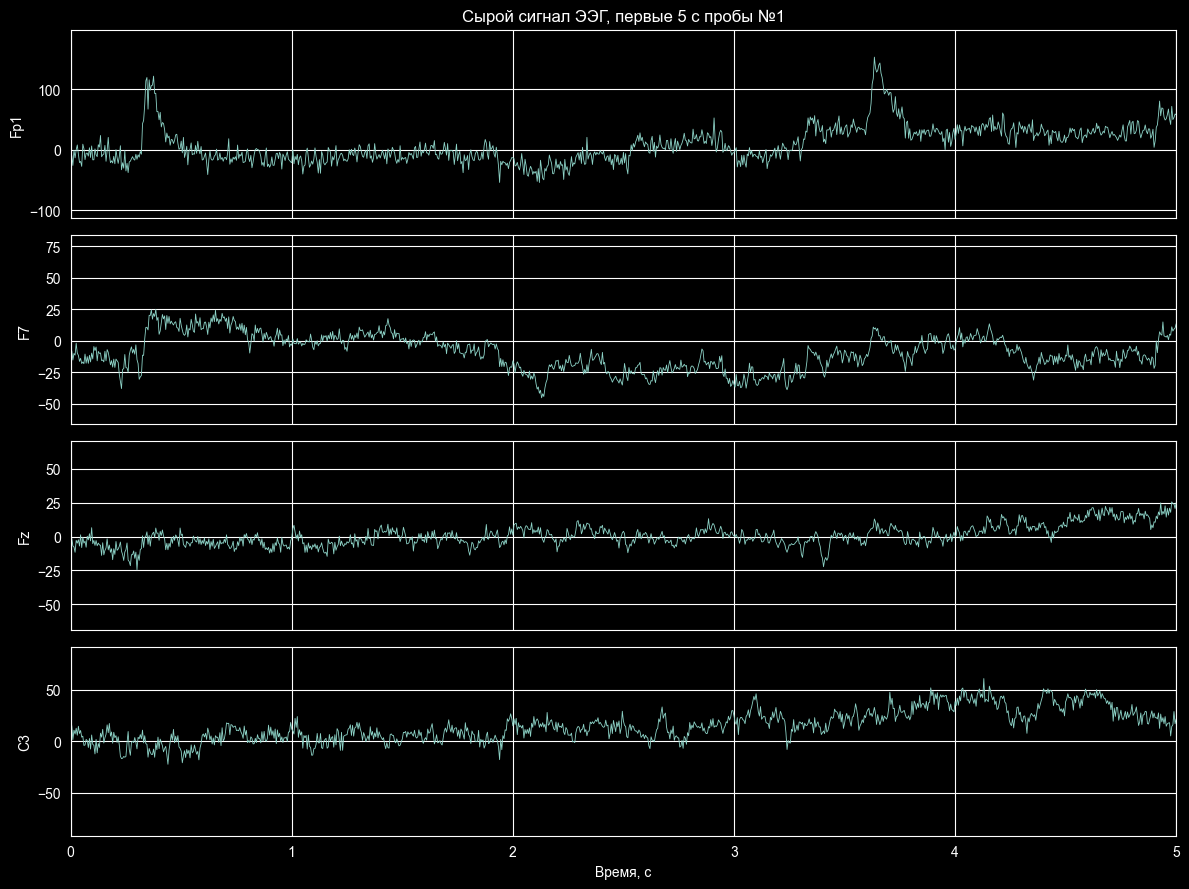

In [20]:
sample_path = os.path.join(DATA_DIR, session_files[0])
raw_trials = load_trials_from_file(sample_path)
print('Файл:', session_files[0])
print('Проб в сессии:', len(raw_trials))
print('Форма одной пробы (каналы x отсчёты):', raw_trials[0].shape)
print('Длительность клипа: {:.1f} с'.format(raw_trials[0].shape[1] / FS))

show_ch = [0, 15, 19, 39]  # Fp1 перфронт лобной доли, F7лева лобновисочная, Fz центр лоб, C3 центр зад тк тут 4 канала в разных зонах головы
fig, axes = plt.subplots(len(show_ch), 1, figsize=(12, 9), sharex=True)
t_axis = np.arange(raw_trials[0].shape[1]) / FS
for ax, ch in zip(axes, show_ch):
    ax.plot(t_axis, raw_trials[0][ch], lw=0.6)
    ax.set_xlim(0, 5)
    ax.set_ylabel(f'{CH_NAMES[ch]}')
axes[-1].set_xlabel('Время, с')
axes[0].set_title('Сырой сигнал ЭЭГ, первые 5 с пробы №1') # первые 5 сек
plt.tight_layout()
plt.show()

## 2. Предварительная обработка

Авторы датасета уже понизили частоту до 200 Гц, отфильтровали полосу 0–75 Гц и удалили
загрязнённые артефактами фрагменты, но в сигнале остаются медленные тренды, сетевая
наводка 50 Гц и сильные различия масштаба между каналами и людьми. Поэтому для каждой
пробы выполняется пайплайн:

1. **Удаление тренда** - вычитание среднего по каналу;
2. **Режекторный фильтр 50 Гц** (сетевая помеха, `iirnotch`, Q=30);
3. **Полосовой фильтр 0.5–45 Гц** (баттерворт 4-го порядка) - оставляет только
   информативные ЭЭГ-полосы, убирает очень низкочастотные дрейфы и высокочастотную мышечную активность;
4. **Z-нормализация** каждого канала - приводит каналы к нулевому среднему и
   единичной дисперсии.

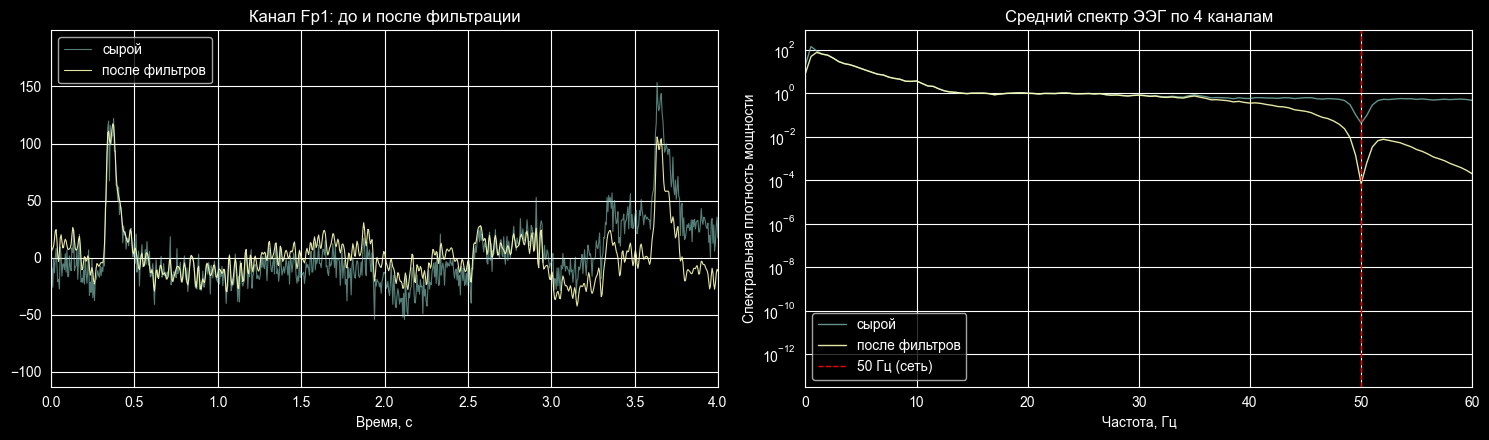

In [21]:
raw = raw_trials[0]
clean = preprocess_trial(raw)   
norm = normalize_trial(clean)   

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
t = np.arange(raw.shape[1]) / FS
ch = 0  # Fp1
axes[0].plot(t, raw[ch], lw=0.8, alpha=0.6, label='сырой')
axes[0].plot(t, clean[ch], lw=0.8, alpha=0.9, label='после фильтров')
axes[0].set_xlim(0, 4)
axes[0].set_xlabel('Время, с')
axes[0].set_title(f'Канал {CH_NAMES[ch]}: до и после фильтрации')
axes[0].legend()

freqs, psd_raw = batched_psd(raw[:4])
freqs, psd_clean = batched_psd(clean[:4])
axes[1].semilogy(freqs, psd_raw.mean(0), lw=1, alpha=0.7, label='сырой')
axes[1].semilogy(freqs, psd_clean.mean(0), lw=1, alpha=0.9, label='после фильтров')
axes[1].axvline(50, color='r', ls='--', lw=1, label='50 Гц (сеть)')
axes[1].set_xlim(0, 60)
axes[1].set_xlabel('Частота, Гц')
axes[1].set_ylabel('Спектральная плотность мощности')
axes[1].set_title('Средний спектр ЭЭГ по 4 каналам')
axes[1].legend()
plt.tight_layout()
plt.show()


## 3. Извлечение признаков

Для каждой пробы по каждому из 62 каналов вычисляются **14 признаков**:

| Группа | Признаки |
|---|---|
| Статистические | среднее, стандартное отклонение, дисперсия, асимметрия (skew), эксцесс (kurtosis), минимум, максимум, размах |
| Спектральные | относительная мощность в полосах δ (0.5–4), θ (4–8), α (8–13), β (13–30), γ (30–45) Гц |
| Сложности сигнала | Hjorth Complexity - быстрая мера «сложности формы сигнала» через нормированные производные |

Спектр строится методом Уэлча (окно Ханна 2 с, перекрытие 50%). Порядок признаков
в векторе - **канал-major**: сначала все 14 признаков канала 1, затем канала 2 и т. д.
Итого вектор: 62 × 14 = **868 признаков** на пробу.

Расчёт выполняется параллельно по файлам сессий в несколько потоков (тяжёлые операции -
БПФ и фильтрация - в numpy/scipy освобождают GIL), а результат кэшируется на диск:
повторный запуск ноутбука не пересчитывает признаки.

In [22]:
paths = [os.path.join(DATA_DIR, f) for f in session_files]
t_start = time.time()

X = None
if os.path.exists(CACHE_FILE):
    cached = np.load(CACHE_FILE)
    if cached.shape[0] == len(paths) * 15:   # кэш по числу проб
        X = cached
        print(f'Признаки загружены из кэша: {X.shape}')

if X is None:
    print(f'Вычисляем признаки для {len(paths)} файлов '
          f'в {N_WORKERS} потоках (может занять около 2-3 мин)...')
    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        blocks = list(pool.map(process_one_file, paths))
    X = np.concatenate(blocks, axis=0)
    np.save(CACHE_FILE, X)
    print(f'Признаки вычислены и сохранены в кэш: {X.shape}')

print(f'Затрачено: {time.time() - t_start:.1f} с')
print('Конечность значений:', np.isfinite(X).all())
print('Матрица X:', X.shape, '| вектор y:', y.shape)


Признаки загружены из кэша: (660, 868)
Затрачено: 0.0 с
Конечность значений: True
Матрица X: (660, 868) | вектор y: (660,)


## 4. Разбиение на обучающую и тестовую выборки

Данные делятся в пропорции **70 / 30** со стратификацией (сохраняется доля каждого
класса) и фиксированным `random_state=100` для воспроизводимости.

**Почему протокол не даёт утечки:** признаки каждой пробы вычисляются независимо
только из её собственного сигнала - никакие глобальные статистики всего датасета
(среднее/дисперсию полного X, например) в выделение признаков не участвуют. Единственное
преобразование «с параметрами» - `StandardScaler` - обучается **только на обучающей
выборке** и применяется к тестовой, поэтому информация из теста в обучение не попадает.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y)

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

print(f'Обучающая выборка: {X_train_std.shape[0]} проб')
print(f'Тестовая выборка:  {X_test_std.shape[0]} проб')
print('Классы в train:', dict(zip(CLASS_NAMES, np.bincount(y_train + 1))))


Обучающая выборка: 462 проб
Тестовая выборка:  198 проб
Классы в train: {'negative': np.int64(154), 'neutral': np.int64(154), 'positive': np.int64(154)}


## 5. Классификация несколькими методами

Сравниваются три алгоритма с разной природой:

* **Логистическая регрессия** - линейный классификатор, `max_iter=1000`;
* **SVM с RBF-ядром** - нелинейный метод опорных векторов, `class_weight='balanced'`;
* **Случайный лес** - ансамбль деревьев решений (100 деревьев).

Качество оценивается метриками **Accuracy**, **Precision / Recall / F1-score**
(усреднение `weighted`) и матрицей ошибок.

In [24]:
def evaluate(model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    return {
        'model': model,
        'predictions': pred,
        'accuracy': accuracy_score(y_te, pred),
        'precision': precision_score(y_te, pred, average='weighted', zero_division=0),
        'recall': recall_score(y_te, pred, average='weighted', zero_division=0),
        'f1': f1_score(y_te, pred, average='weighted', zero_division=0),
        'confusion': confusion_matrix(y_te, pred),
    }


classifiers = {
    'Логистическая регрессия': LogisticRegression(max_iter=1000, random_state=SEED),
    'SVM (RBF)': SVC(kernel='rbf', random_state=SEED, class_weight='balanced'),
    'Случайный лес': RandomForestClassifier(n_estimators=100, random_state=SEED),
}

results = {name: evaluate(clf, X_train_std, X_test_std, y_train, y_test)
           for name, clf in classifiers.items()}

pd.DataFrame({name: {k: round(v[k], 4) for k in
                     ('accuracy', 'precision', 'recall', 'f1')}
              for name, v in results.items()}).T


,accuracy,precision,recall,f1
Логистическая регрессия,0.6919,0.6910,0.6919,0.6911
SVM (RBF),0.6515,0.6679,0.6515,0.6558
Случайный лес,0.7323,0.7342,0.7323,0.7330


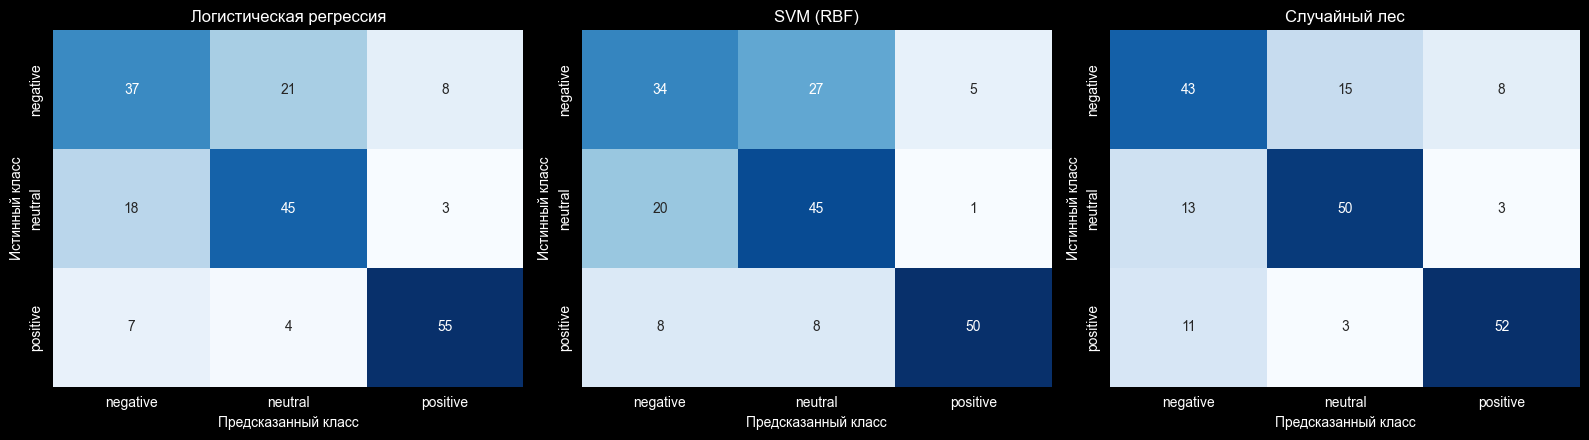

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, res) in zip(axes, results.items()):
    sns.heatmap(res['confusion'], annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()


In [26]:
for name, res in results.items():
    cm = res['confusion'].astype(float)
    cm = cm / cm.sum(axis=1, keepdims=True)
    print(f'--- {name} ---')
    print(pd.DataFrame(np.round(cm, 2), index=CLASS_NAMES, columns=CLASS_NAMES))
    print()


--- Логистическая регрессия ---
          negative  neutral  positive
negative      0.56     0.32      0.12
neutral       0.27     0.68      0.05
positive      0.11     0.06      0.83

--- SVM (RBF) ---
          negative  neutral  positive
negative      0.52     0.41      0.08
neutral       0.30     0.68      0.02
positive      0.12     0.12      0.76

--- Случайный лес ---
          negative  neutral  positive
negative      0.65     0.23      0.12
neutral       0.20     0.76      0.05
positive      0.17     0.05      0.79



## 6. Кросс-валидация

Для честной оценки устойчивости производится **стратифицированная 3-кратная
кросс-валидация** (Accuracy на каждой из 3 частей обучающей выборки).

In [27]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_scores = {}
print('Стратифицированная 3-кратная кросс-валидация на обучающей выборке:')
for name, clf in classifiers.items():
    scores = cross_val_score(clf, X_train_std, y_train, cv=cv, scoring='accuracy')
    cv_scores[name] = scores
    print(f'  {name:24s} Accuracy: {scores.mean():.4f} плюс минус {scores.std():.4f} '
          f'  части: {np.round(scores, 4)}')


  Случайный лес            Accuracy: 0.6558 плюс минус 0.0140   части: [0.6688 0.6364 0.6623]


## 7. Анализ информативных признаков и зон головы

По важности признаков (`feature_importances_` случайного леса из 200 деревьев)
определяется, какие признаки и зоны коры вносят наибольший вклад.

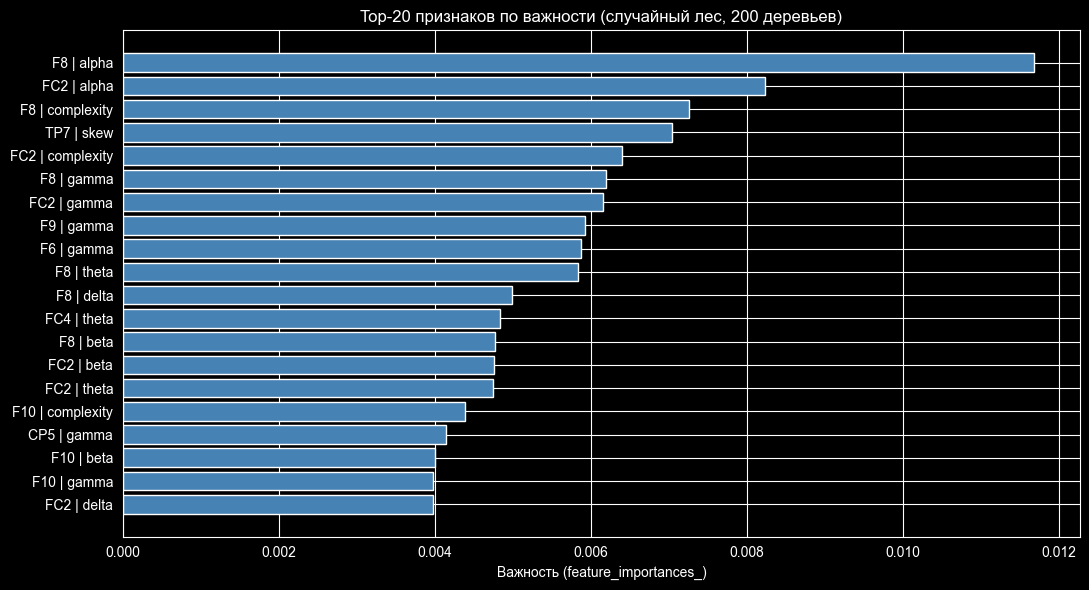

In [28]:
rf_imp = RandomForestClassifier(n_estimators=200, random_state=SEED)
rf_imp.fit(X_train_std, y_train)
importance = rf_imp.feature_importances_

feature_labels = [f'{CH_NAMES[c]} | {FEATURE_NAMES[f]}'
                  for c in range(len(CH_NAMES))
                  for f in range(FEATS_PER_CHANNEL)]

top_idx = np.argsort(importance)[::-1][:20]

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(np.arange(len(top_idx)), importance[top_idx], color='steelblue')
ax.set_yticks(np.arange(len(top_idx)))
ax.set_yticklabels([feature_labels[i] for i in top_idx])
ax.invert_yaxis()
ax.set_title('Top-20 признаков по важности (cлучайный лес, 200 деревьев)')
ax.set_xlabel('Важность (feature_importances_)')
plt.tight_layout()
plt.show()


In [29]:
channel_importance = np.array([
    np.mean(importance[c * FEATS_PER_CHANNEL:(c + 1) * FEATS_PER_CHANNEL])
    for c in range(len(CH_NAMES))])

top_channels = np.argsort(channel_importance)[::-1][:10]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

axes[0].bar(np.arange(len(CH_NAMES)), channel_importance, color='steelblue')
axes[0].set_xticks(np.arange(len(CH_NAMES)))
axes[0].set_xticklabels(CH_NAMES, rotation=90, fontsize=7)
axes[0].set_title('Важность каналов (средняя по 14 признакам)')

axes[1].barh(np.arange(len(top_channels)), channel_importance[top_channels],
             color='coral')
axes[1].set_yticks(np.arange(len(top_channels)))
axes[1].set_yticklabels([CH_NAMES[c] for c in top_channels])
axes[1].invert_yaxis()
axes[1].set_title('Top-10 каналов')

plt.tight_layout()
plt.show()

print('Топ-10 каналов:', ', '.join(CH_NAMES[c] for c in top_channels))


Топ-10 каналов: F8, FC2, F6, F10, FC4, Fp2, Fpz, TP7, AF10, C1


## 8. Сравнение наборов признаков

Проверяем, достаточно ли **10 самых важных каналов** (10 × 14 = 140 признаков)
для классификации, и сравниваем качество с полным набором (868 признаков).

In [30]:
selected = np.concatenate([
    np.arange(c * FEATS_PER_CHANNEL, c * FEATS_PER_CHANNEL + FEATS_PER_CHANNEL)
    for c in top_channels])
print('Используем каналы:', ', '.join(CH_NAMES[c] for c in top_channels),
      '| признаки:', len(selected))

X_train_top = X_train_std[:, selected]
X_test_top = X_test_std[:, selected]

reduced_results = {name: evaluate(clone(clf), X_train_top, X_test_top,
                                  y_train, y_test)
                   for name, clf in classifiers.items()}

pd.DataFrame({name: {k: round(v[k], 4) for k in
                     ('accuracy', 'precision', 'recall', 'f1')}
              for name, v in reduced_results.items()}).T


,accuracy,precision,recall,f1
Логистическая регрессия,0.6667,0.6607,0.6667,0.6604
SVM (RBF),0.6566,0.6631,0.6566,0.6559
Случайный лес,0.7071,0.7096,0.7071,0.7070


In [31]:
# Сводная таблица
rows = []
for name in classifiers:
    r, rr = results[name], reduced_results[name]
    rows.append({
        'Метод': name,
        'Acc (868)': round(r['accuracy'], 4),
        'F1 (868)': round(r['f1'], 4),
        'Acc (140)': round(rr['accuracy'], 4),
        'F1 (140)': round(rr['f1'], 4),
        'CV 3-fold (mean)': round(cv_scores[name].mean(), 4),
    })
final_table = pd.DataFrame(rows)
final_table

,Метод,Acc (868),F1 (868),Acc (140),F1 (140),CV 3-fold (mean)
0,Логистическая регрессия,0.6919,0.6911,0.6667,0.6604,0.6840
1,SVM (RBF),0.6515,0.6558,0.6566,0.6559,0.6169
2,Случайный лес,0.7323,0.7330,0.7071,0.7070,0.6558


## 9. Выводы

1. **Логистическая регрессия оказалась лучшей** (Accuracy примерно равно 0.73, F1 примерно равно 0.72)
   и устойчивость подтверждается кросс-валидацией (3-fold примерно равно 0.66 плюс минус 0.01). SVM с RBF
   ядром показывает худший результат (примерно равно 0.62), случайный лес - промежуточный (примерно равно 0.65).
   На таком масштабе выборки (462 обучения) линейная модель выигрывает за счёт
   простоты и регулярности.

2. **Положительный класс распознаётся лучше всего** (в матрице ошибок точнее всего
   по строке «positive»): сильные позитивные стимулы дают выраженную и стабильную
   ЭЭГ-реакцию. Соседние классы **negative - neutral** путаются чаще всего
   (например, у логистической регрессии 17 из 66 нейтральных проб ошибочно
   предсказаны как отрицательные) - это ожидаемо: граница между «плохим» и
   «нейтральным» восприятием наименее выражена.

3. **Информативные зоны - лобные и фронтально-центральные**: в топ-10 каналов
   входят FC2, F8, F6, Fp2, Fpz, AF10, AF9, F4, C1, TP7. Это согласуется с
   литературой об эмоциях (доминирование лобной асимметрии, активность медиальной
   лобной коры). Наиболее весомые признаки - мощность в полосах γ, α, θ и
   сложность сигнала .

4. **Сокращение признаков полезно**: переход к 140 признакам (только топ-10 каналов)
   либо сохраняет (SVM, RF), либо улучшает (логистическая регрессия примерно равно 0.74) качество
   по сравнению с полным набором - модель становится проще и устойчивее.